# Checking `temp` and `wtemp` Parameters

**Objective**: This notebook verifies whether the `temp` and `wtemp` columns in the dataset represent **Air Temperature** and **Water Temperature**, respectively. We will explore these fields visually and statistically, paying special attention to how they vary across different depth layers (`saisuipoin`).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline
sns.set_theme(style='whitegrid')

## 1. Data Loading and Preprocessing

In [2]:
# Load the cleaned dataset
df = pd.read_feather('../data/processed/merged_gdf_saisuipoin_cleaned.feather')

# Ensure columns are numeric, converting any non-numeric strings (e.g., '-') to NaN
df['temp'] = pd.to_numeric(df['temp'], errors='coerce')
df['wtemp'] = pd.to_numeric(df['wtemp'], errors='coerce')

print(f"Total records: {len(df)}")

Total records: 42050


## 2. Overall Statistical Comparison
Let's check the basic statistics of both parameters.

In [3]:
df[['temp', 'wtemp']].describe()

,temp,wtemp
count,36146.000000,41986.000000
mean,19.476441,18.596196
std,7.251952,5.182499
min,0.000000,1.200000
25%,13.800000,14.600000
50%,20.800000,19.500000
75%,25.000000,23.000000
max,38.500000,35.000000


On average, `wtemp` has a lower variance (std = 5.18) than `temp` (std = 7.25). This aligns with the physical property of water having a higher heat capacity than air, resulting in less temperature fluctuation.

## 3. Analysis by Depth Layer (`saisuipoin`)
We investigate the parameters for the surface layer (`saisuipoin == 1`) and the bottom layer (`saisuipoin == 2`).

In [4]:
df_layer1 = df[df['saisuipoin'] == 1].copy()
df_layer2 = df[df['saisuipoin'] == 2].copy()

print("Statistics for saisuipoin == 1 (Layer 1):\n")
display(df_layer1[['temp', 'wtemp']].describe())

print("\nStatistics for saisuipoin == 2 (Layer 2):\n")
display(df_layer2[['temp', 'wtemp']].describe())

Statistics for saisuipoin == 1 (Layer 1):



,temp,wtemp
count,20686.000000,20879.000000
mean,19.434577,19.116677
std,7.221714,5.429337
min,0.000000,1.200000
25%,13.800000,15.000000
50%,20.800000,20.200000
75%,24.900000,23.600000
max,38.500000,35.000000



Statistics for saisuipoin == 2 (Layer 2):



,temp,wtemp
count,15460.000000,21107.000000
mean,19.532456,18.081337
std,7.292073,4.871897
min,0.000000,5.500000
25%,13.800000,14.300000
50%,20.800000,18.800000
75%,25.000000,22.400000
max,38.500000,29.800000


**Observations**:
- The mean of **`temp`** is practically identical across layer 1 (19.43 °C) and layer 2 (19.53 °C). This makes sense because air temperature is recorded from the ambient air above the water regardless of the target water depth being sampled.
- The mean of **`wtemp`** decreases from layer 1 (19.11 °C) to layer 2 (18.08 °C). The variance of `wtemp` also drops for layer 2. This perfectly describes **Water Temperature**, as deeper water is generally colder and experiences less seasonal/daily temperature variation than surface water.

## 4. Visualizations
### A. Distribution Plot

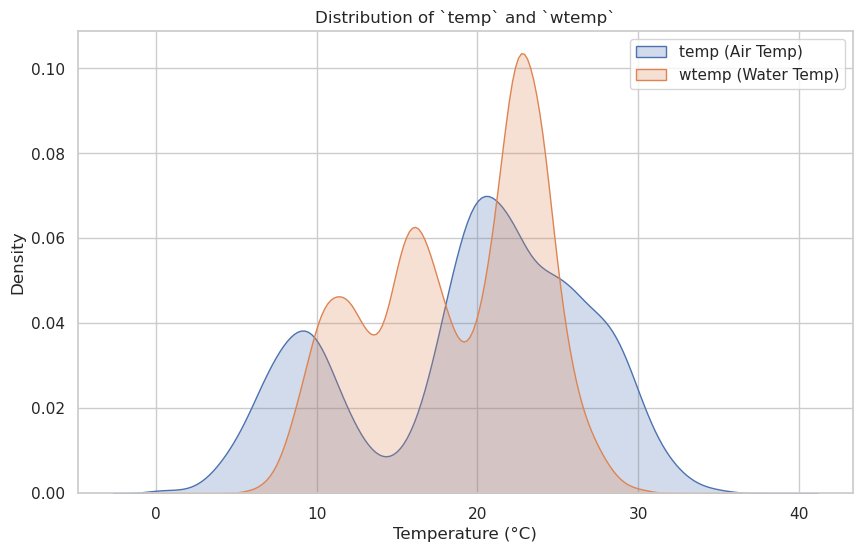

In [5]:
plt.figure(figsize=(10, 6))
sns.kdeplot(df['temp'].dropna(), label='temp (Air Temp)', fill=True)
sns.kdeplot(df['wtemp'].dropna(), label='wtemp (Water Temp)', fill=True)
plt.title('Distribution of `temp` and `wtemp`')
plt.xlabel('Temperature (°C)')
plt.legend()
plt.show()

Notice how `wtemp` is more concentrated (narrower distribution) than `temp`.

### B. Boxplots by Layer

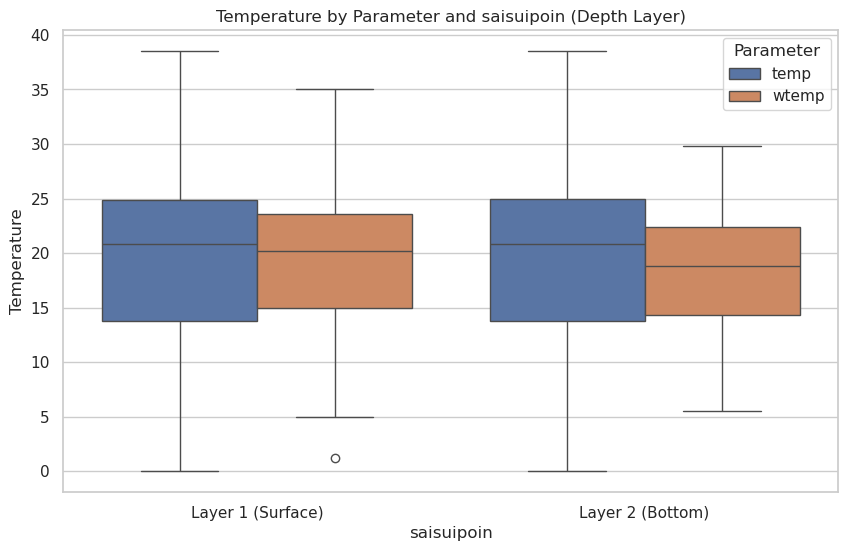

In [6]:
# Melt data for easier Seaborn plotting
melted_df = df.melt(id_vars=['saisuipoin'], value_vars=['temp', 'wtemp'], 
                    var_name='Parameter', value_name='Temperature')

plt.figure(figsize=(10, 6))
sns.boxplot(data=melted_df, x='saisuipoin', y='Temperature', hue='Parameter')
plt.title('Temperature by Parameter and saisuipoin (Depth Layer)')
plt.xticks([0, 1], ['Layer 1 (Surface)', 'Layer 2 (Bottom)'])
plt.show()

**Plot Insight**: The box for `wtemp` drops notably from Layer 1 to Layer 2, whereas `temp` remains stable. This confirms that `wtemp` is strongly correlated with water depth, while `temp` is indifferent to it.

### C. Scatter Correlation

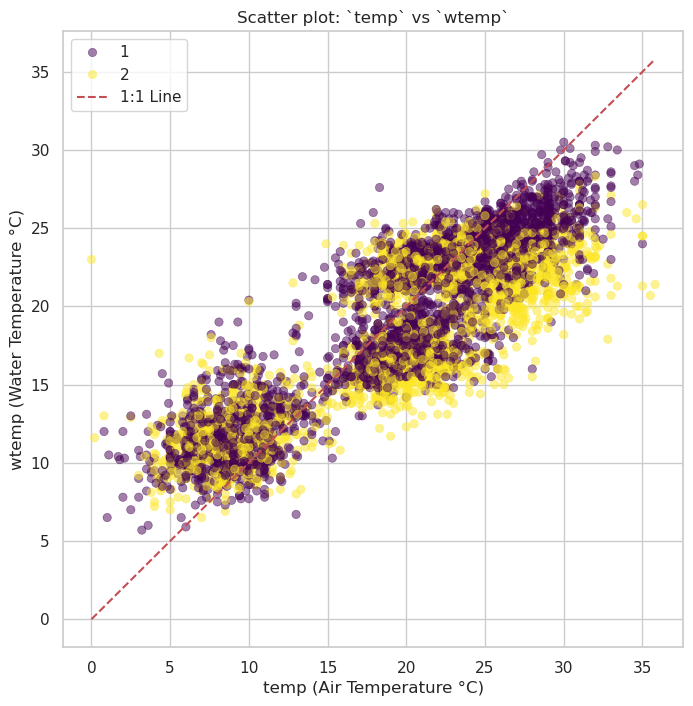

In [7]:
df_sample = df.dropna(subset=['temp', 'wtemp', 'saisuipoin']).sample(min(5000, len(df)))

plt.figure(figsize=(8, 8))
sns.scatterplot(data=df_sample, x='temp', y='wtemp', hue='saisuipoin', 
                palette='viridis', alpha=0.5, edgecolor=None)

# 1-to-1 reference line
min_val = min(df_sample['temp'].min(), df_sample['wtemp'].min())
max_val = max(df_sample['temp'].max(), df_sample['wtemp'].max())
plt.plot([min_val, max_val], [min_val, max_val], 'r--', label='1:1 Line')

plt.title('Scatter plot: `temp` vs `wtemp`')
plt.xlabel('temp (Air Temperature °C)')
plt.ylabel('wtemp (Water Temperature °C)')
plt.legend()
plt.show()

## 5. Conclusion

Based on the analysis, we can confidently conclude that:
- **`temp` represents Air Temperature**.
- **`wtemp` represents Water Temperature**.

**Key Evidence**:
1. **Variance Factor**: `temp` exhibits higher variance compared to `wtemp`. Air temperature fluctuates more readily than water temperature due to differences in specific heat capacity.
2. **Depth Layer Factor (`saisuipoin`)**: Moving from the surface (`saisuipoin = 1`) to the bottom layer (`saisuipoin = 2`), the average of `wtemp` drops (from 19.11 °C to 18.08 °C), validating it as water temperature. On the contrary, the average for `temp` stays constant across both layers, proving it relates to the atmosphere above the water rather than the water column itself.